# Auditoría progresiva IL-CLDM (ROI)

Bitácora de los cambios de stage 2 sobre el parent `calib_roi3ch_uni_rois_reproc` (`data_rois/`, volumen 96×112×114). Cada etapa nueva se agrega al final de `STAGES` en la celda siguiente. Las curvas, la tabla y las imágenes se rehacen solas.

El corte de esta serie es el error de predecir la media del latente ROI reproc: **MSE 4.09** (`std²` de `data_info/latent_stats_latent_Abeta_rois_reproc.json`).

Etiquetas: `0` control, `1` Parkinson.

Para incorporar el próximo cambio:

1. Entrenar el run y, si hay imágenes, correr inferencia con `--save-synthetic-spect` sobre test (y train si se quiere clasificación).
2. Añadir un diccionario a `STAGES` con `exp`, `run_id`, `early_stop` (`image` o `latent`) y una frase en `change`.
3. Volver a ejecutar el notebook desde arriba.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd

HERE = Path.cwd().resolve()
ROOT = HERE if (HERE / "experiments").is_dir() else HERE.parent
# `code` es también un módulo de la biblioteca estándar. Importar `code.stage2_report_utils`
# choca con él. Se carga el archivo de IL-CLDM/code/ por su ruta.
for path in (ROOT, ROOT / "code"):
    path_str = str(path)
    if path_str not in sys.path:
        sys.path.insert(0, path_str)

from stage2_report_utils import (
    LABEL_NAMES,
    load_classification_metrics_for,
    load_inference_reconstruction_for,
    load_synthetic_volume_for,
    load_training_frames_for,
    training_checkpoint_summary,
)

MEAN_PREDICTOR_MSE = 4.09
GT_SPECT_DIR = ROOT / "data_rois" / "whole_Abeta"

# Orden cronológico. No reordenar: las gráficas siguen esta secuencia.
STAGES = [
    {
        "key": "baseline",
        "title": "0 · Línea base",
        "change": "Objetivo epsilon + MSE. Encoder MRI congelado, concat de un canal, FiLM off.",
        "exp": "exp_nm_s2_frozen_calib_roi3ch_uni_rois_reproc",
        "run_id": "calib_roi3ch_uni_rois_reproc",
        "early_stop": "image",
    },
    {
        "key": "eps_x0",
        "title": "1 · eps + x0",
        "change": "Sigue prediciendo ruido. En cada paso: MSE(ε) + 5·L1 del latente limpio.",
        "exp": "exp_nm_s2_frozen_calib_roi3ch_uni_rois_reproc_eps_x0",
        "run_id": "calib_roi3ch_uni_rois_reproc_eps_x0",
        "early_stop": "latent",
    },
    {
        "key": "x0",
        "title": "2 · solo x0",
        "change": "La red predice el latente limpio con L1. La MSE del ruido no entra.",
        "exp": "exp_nm_s2_frozen_calib_roi3ch_uni_rois_reproc_x0",
        "run_id": "calib_roi3ch_uni_rois_reproc_x0",
        "early_stop": "latent",
    },
    {
        "key": "x0_minmax_kl",
        "title": "3 · x0 minmax+KL",
        "change": "AAE nuevos con KL hacia N(0,1). Imagen con percentiles fijos a [0,1]. Difusión x0 sin z-score del latente, clamp ±4.",
        "exp": "exp_nm_s2_frozen_calib_roi3ch_uni_rois_reproc_x0_minmax_kl",
        "run_id": "calib_roi3ch_uni_rois_reproc_x0_minmax_kl",
        "early_stop": "latent",
        "latent_report": "data_rois/latent_Abeta_minmax_kl/latent_mu_report.json",
    },
]

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 140)
print(f"ROOT = {ROOT}")
print(f"Etapas: {', '.join(s['key'] for s in STAGES)}")

ROOT = /workspace/IL-CLDM
Etapas: baseline, eps_x0, x0, x0_minmax_kl


## Curvas de entrenamiento

La pérdida principal no tiene el mismo nombre en todas las etapas: `MSE_loss` cuando la red predice ruido, `x0_l1` cuando predice el latente limpio. Por eso cada etapa va en su propio eje. Latente, SSIM y PSNR de validación sí comparten eje, con la línea de predecir la media en el MSE latente.

Sin curvas: eps_x0


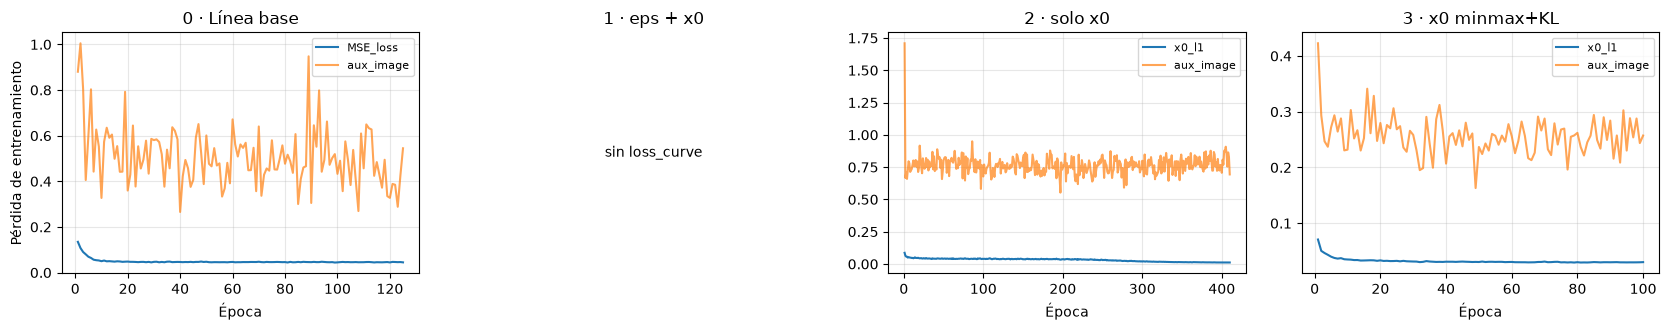

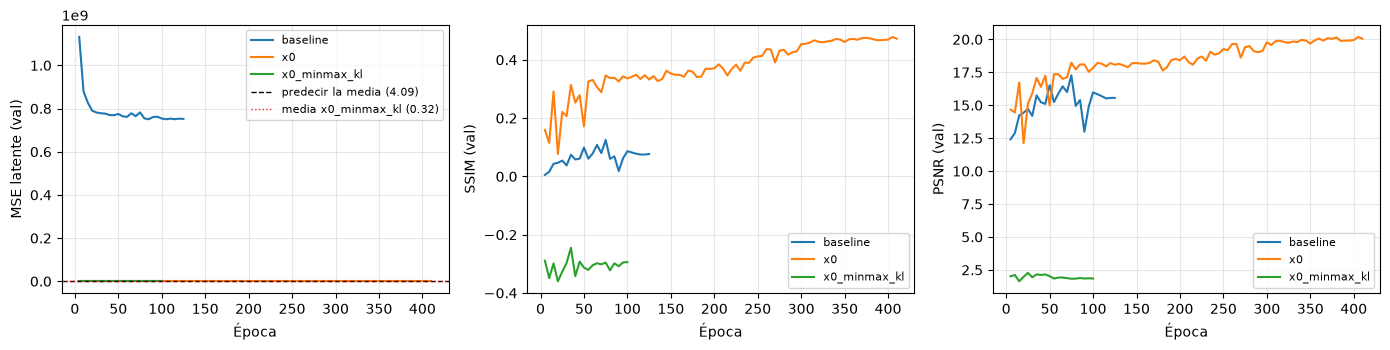

In [2]:
import json

def primary_loss_column(df: pd.DataFrame) -> str | None:
    for name in ("x0_l1", "MSE_loss", "latent_loss"):
        if name in df.columns:
            return name
    numeric = [c for c in df.columns if c != "Epoch"]
    return numeric[0] if numeric else None


frames = {}
missing = []
for stage in STAGES:
    loaded = load_training_frames_for(stage["exp"])
    if not loaded:
        missing.append(stage["key"])
    frames[stage["key"]] = loaded
if missing:
    print("Sin curvas:", ", ".join(missing))

n = len(STAGES)
fig, axes = plt.subplots(1, n, figsize=(4.2 * n, 3.4), sharey=False)
if n == 1:
    axes = [axes]
for ax, stage in zip(axes, STAGES):
    loss = frames[stage["key"]].get("loss_curve")
    ax.set_title(stage["title"])
    if loss is None or loss.empty:
        ax.text(0.5, 0.5, "sin loss_curve", ha="center", va="center")
        ax.set_axis_off()
        continue
    col = primary_loss_column(loss)
    ax.plot(loss["Epoch"], loss[col], label=col)
    if "latent_loss" in loss.columns and col != "latent_loss":
        ax.plot(loss["Epoch"], loss["latent_loss"], label="latent_loss", alpha=0.85)
    if "aux_image_loss" in loss.columns:
        ax.plot(loss["Epoch"], loss["aux_image_loss"], label="aux_image", alpha=0.7)
    ax.set_xlabel("Época")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel("Pérdida de entrenamiento")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for stage in STAGES:
    val = frames[stage["key"]].get("validation_latent")
    if val is None or val.empty:
        continue
    axes[0].plot(val["Epoch"], val["latent_MSE"], label=stage["key"])
    axes[1].plot(val["Epoch"], val["SSIM"], label=stage["key"])
    axes[2].plot(val["Epoch"], val["PSNR"], label=stage["key"])
axes[0].axhline(MEAN_PREDICTOR_MSE, color="black", ls="--", lw=1, label="predecir la media (4.09)")
for stage in STAGES:
    report_path = stage.get("latent_report")
    if not report_path:
        continue
    path = ROOT / report_path
    if not path.is_file():
        continue
    variance = float(json.loads(path.read_text())["variance"])
    axes[0].axhline(variance, color="tab:red", ls=":", lw=1, label=f"media {stage['key']} ({variance:.2f})")
axes[0].set_ylabel("MSE latente (val)")
axes[1].set_ylabel("SSIM (val)")
axes[2].set_ylabel("PSNR (val)")
for ax in axes:
    ax.set_xlabel("Época")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Checkpoint elegido

Una fila por etapa, en la época que usó el early stopping. `image` elige el mayor PSNR+SSIM de validación. `latent` elige el menor MSE latente de validación. Las columnas de test son el muestreo hecho en esa misma época durante el entrenamiento.

In [3]:
rows = []
for stage in STAGES:
    pack = frames[stage["key"]]
    val = pack.get("validation")
    test = pack.get("test")
    if val is None or test is None or val.empty or test.empty:
        rows.append({"etapa": stage["key"], "cambio": stage["change"], "nota": "sin validation/test"})
        continue
    summary = training_checkpoint_summary(
        val,
        test,
        criterion=stage["early_stop"],
        validation_latent=pack.get("validation_latent"),
        test_latent=pack.get("test_latent"),
    )
    summary["etapa"] = stage["key"]
    summary["cambio"] = stage["change"]
    summary["supera_media"] = summary["test_latent_mse_at_best"] < MEAN_PREDICTOR_MSE
    rows.append(summary)

checkpoint_table = pd.DataFrame(rows)
show_cols = [
    "etapa",
    "best_epoch",
    "early_stop_criterion",
    "val_latent_mse",
    "test_latent_mse_at_best",
    "supera_media",
    "test_psnr_at_best",
    "test_ssim_at_best",
    "last_epoch",
    "cambio",
]
show_cols = [c for c in show_cols if c in checkpoint_table.columns]
checkpoint_table[show_cols]

,etapa,best_epoch,early_stop_criterion,val_latent_mse,test_latent_mse_at_best,supera_media,test_psnr_at_best,test_ssim_at_best,last_epoch,cambio
0,baseline,75.0,image,NaN,7.826140e+08,False,17.257559,0.124382,125.0,"Objetivo epsilon + MSE. Encoder MRI congelado, concat de un canal, FiLM off."
1,eps_x0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Sigue prediciendo ruido. En cada paso: MSE(ε) + 5·L1 del latente limpio.
2,x0,360.0,latent,1.087901,1.081087e+00,True,20.086765,0.476324,410.0,La red predice el latente limpio con L1. La MSE del ruido no entra.
3,x0_minmax_kl,50.0,latent,0.169898,1.656141e-01,True,1.995265,-0.298471,100.0,"AAE nuevos con KL hacia N(0,1). Imagen con percentiles fijos a [0,1]. Difusión x0 sin z-score del latente, clamp ±4."


## Inferencia en test y clasificación

PSNR y SSIM salen de `reconstruction_metrics.csv` (media sobre los sujetos de test). La clasificación solo aparece si el run tiene embeddings de train y de test. Si una etapa todavía no tiene esa pasada, la fila lo dice y el resto del notebook sigue.

In [4]:
recon = {}
recon_rows = []
class_frames = []
for stage in STAGES:
    key, exp, run_id = stage["key"], stage["exp"], stage["run_id"]
    try:
        df = load_inference_reconstruction_for(exp, run_id, key)
    except FileNotFoundError:
        recon_rows.append({"etapa": key, "n_test": 0, "nota": "sin inferencia de test"})
        continue
    recon[key] = df
    row = {"etapa": key, "n_test": int(len(df))}
    for col in ("PSNR", "SSIM", "PSNR_roi", "SSIM_roi"):
        if col in df.columns:
            row[col] = float(df[col].mean())
    recon_rows.append(row)
    try:
        clf = load_classification_metrics_for(exp, run_id, key)
        clf.insert(0, "etapa", key)
        class_frames.append(clf)
    except FileNotFoundError:
        pass

recon_table = pd.DataFrame(recon_rows)
display(recon_table)

if class_frames:
    clf_table = pd.concat(class_frames, ignore_index=True)
    keep = [c for c in ["etapa", "model", "balanced_accuracy", "f1", "recall", "precision", "roc_auc", "accuracy"] if c in clf_table.columns]
    display(clf_table[keep].sort_values(["etapa", "balanced_accuracy"], ascending=[True, False]))
else:
    print("Ninguna etapa tiene classification/classification_metrics.csv todavía.")

,etapa,n_test,PSNR,SSIM,PSNR_roi,SSIM_roi,nota
0,baseline,34,17.235735,0.123500,21.356412,0.735176,NaN
1,eps_x0,0,NaN,NaN,NaN,NaN,sin inferencia de test
2,x0,34,20.044912,0.472647,24.074824,0.842441,NaN
3,x0_minmax_kl,0,NaN,NaN,NaN,NaN,sin inferencia de test


,etapa,model,balanced_accuracy,f1,recall,precision,roc_auc,accuracy
0,baseline,KNN_auto,0.582143,0.760000,0.95,0.633333,0.653571,0.647059
1,baseline,DNN_simple,0.546429,0.529412,0.45,0.642857,0.510714,0.529412
2,baseline,KNN_K2,0.542857,0.695652,0.80,0.615385,0.587500,0.588235
3,baseline,SVM_RBF,0.500000,0.740741,1.00,0.588235,0.482143,0.588235
4,baseline,SVM_linear,0.475000,0.716981,0.95,0.575758,0.467857,0.558824
5,baseline,LogisticRegression,0.450000,0.692308,0.90,0.562500,0.535714,0.529412
6,x0,DNN_simple,0.628571,0.533333,0.40,0.800000,0.664286,0.588235
7,x0,LogisticRegression,0.517857,0.357143,0.25,0.625000,0.557143,0.470588
8,x0,KNN_K2,0.496429,0.437500,0.35,0.583333,0.469643,0.470588
9,x0,KNN_auto,0.457143,0.285714,0.20,0.500000,0.446429,0.411765


## Un control y un Parkinson

Los dos sujetos se eligen en el test, uno por clase, cerca de la mediana de PSNR de la última etapa que ya tiene imágenes. Se mantienen fijos mientras esa etapa no cambie, así las modificaciones siguientes se ven sobre los mismos casos.

La figura es de **2 × (n + 1)**: una fila por sujeto (control arriba, Parkinson abajo) y `n + 1` columnas, donde `n` es el número de etapas en `STAGES` y la columna extra es el SPECT real. El corte es el axial central. La ventana de cada fila es la del SPECT real de ese sujeto (percentiles 1 y 99).

Casos anclados a la mediana de PSNR de 'x0': [('3759', 'control'), ('3593', 'parkinson')]


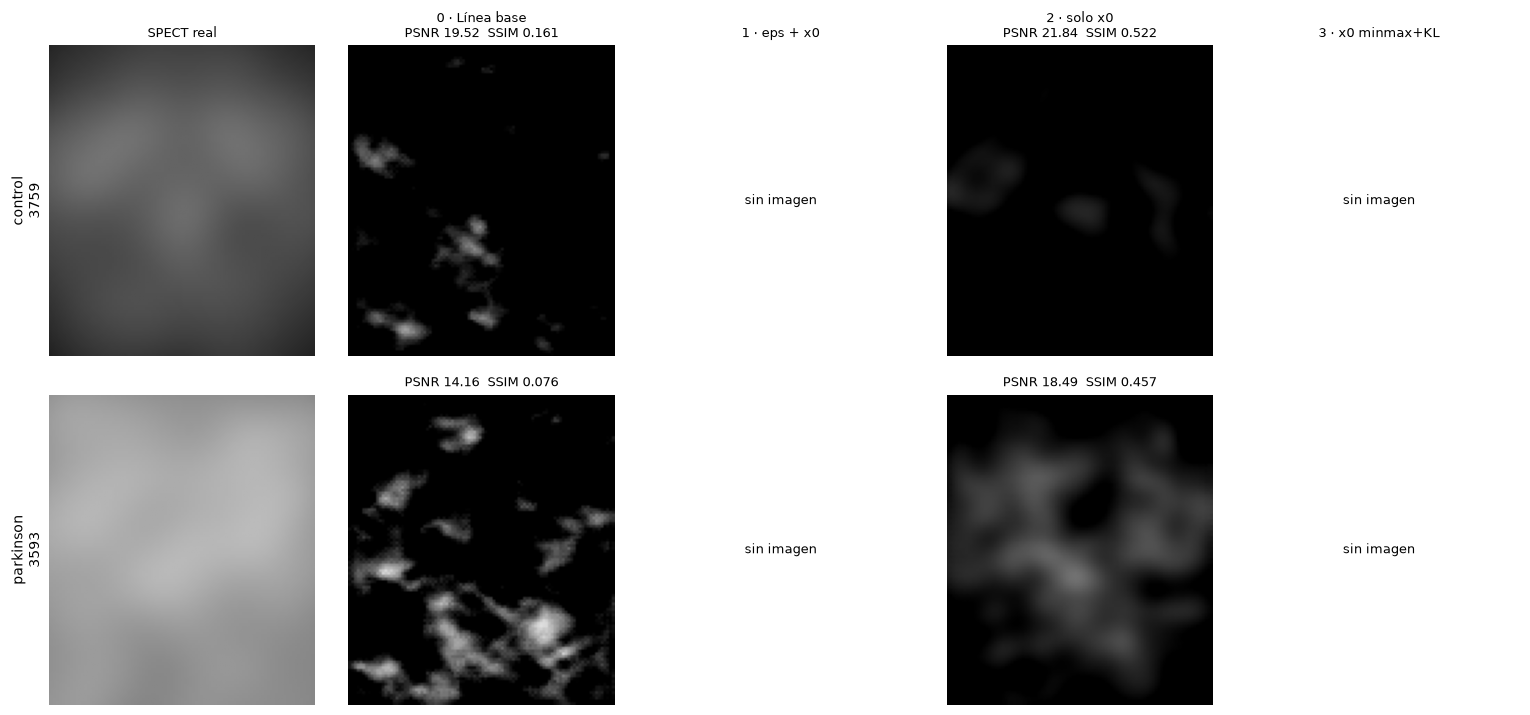

In [5]:
def load_gt(subject_id: str) -> np.ndarray:
    path = GT_SPECT_DIR / f"{subject_id}.nii.gz"
    vol = nib.load(str(path)).get_fdata(dtype=np.float32)
    return vol[0] if vol.ndim == 4 else vol


def axial_mid(vol: np.ndarray) -> np.ndarray:
    vol = np.asarray(vol)
    if vol.ndim == 4:
        vol = vol[0]
    return vol[:, :, vol.shape[-1] // 2]


def pick_subject(df: pd.DataFrame, label: float) -> str | None:
    subset = df[df["label"] == label]
    if subset.empty or "PSNR" not in subset.columns:
        return None
    target = float(subset["PSNR"].median())
    idx = (subset["PSNR"] - target).abs().idxmin()
    return str(subset.loc[idx, "ID"])


anchor = None
for stage in reversed(STAGES):
    if stage["key"] in recon and not recon[stage["key"]].empty:
        anchor = recon[stage["key"]]
        anchor_key = stage["key"]
        break

if anchor is None:
    print("Todavía no hay reconstrucciones de test para elegir casos.")
else:
    cases = []
    for label, name in LABEL_NAMES.items():
        sid = pick_subject(anchor, label)
        if sid is not None:
            cases.append((sid, name))
    print(f"Casos anclados a la mediana de PSNR de '{anchor_key}':", cases)

    # 2 filas (control, Parkinson) × (n + 1) columnas: SPECT real y cada etapa.
    columns = [("SPECT real", None)] + [(s["title"], s) for s in STAGES]
    n_rows, n_cols = len(cases), len(columns)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.1 * n_cols, 3.6 * n_rows))
    axes = np.atleast_2d(axes)

    def _frame(ax):
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)

    for row, (sid, name) in enumerate(cases):
        gt = load_gt(sid)
        vmin, vmax = np.percentile(gt, [1, 99])
        for col, (title, stage) in enumerate(columns):
            ax = axes[row, col]
            _frame(ax)
            if stage is None:
                img = axial_mid(gt)
                metric = ""
            else:
                try:
                    syn = load_synthetic_volume_for(stage["exp"], stage["run_id"], sid)
                    img = axial_mid(syn)
                except FileNotFoundError:
                    ax.set_title(title if row == 0 else "", fontsize=9)
                    ax.text(
                        0.5,
                        0.5,
                        "sin imagen",
                        ha="center",
                        va="center",
                        transform=ax.transAxes,
                        fontsize=9,
                    )
                    if col == 0:
                        ax.set_ylabel(f"{name}\n{sid}", fontsize=10)
                    continue
                metric = ""
                if stage["key"] in recon:
                    hit = recon[stage["key"]]
                    hit = hit[hit["ID"].astype(str) == sid]
                    if len(hit):
                        metric = f"\nPSNR {hit['PSNR'].iloc[0]:.2f}  SSIM {hit['SSIM'].iloc[0]:.3f}"
            ax.imshow(np.rot90(img), cmap="gray", vmin=vmin, vmax=vmax)
            ax.set_title((title if row == 0 else "") + metric, fontsize=9)
            if col == 0:
                ax.set_ylabel(f"{name}\n{sid}", fontsize=10)
    fig.tight_layout()
    plt.show()

## Corte axial a elección

La figura anterior usa el axial central. Aquí se repite la misma rejilla de 2 × (n + 1) con el índice de `SLICE_INDEX` sobre el último eje del volumen.

`None` vuelve al corte central. Un entero entre `0` y `profundidad - 1` elige ese corte. La ventana de cada fila sigue siendo la del SPECT real de ese sujeto.

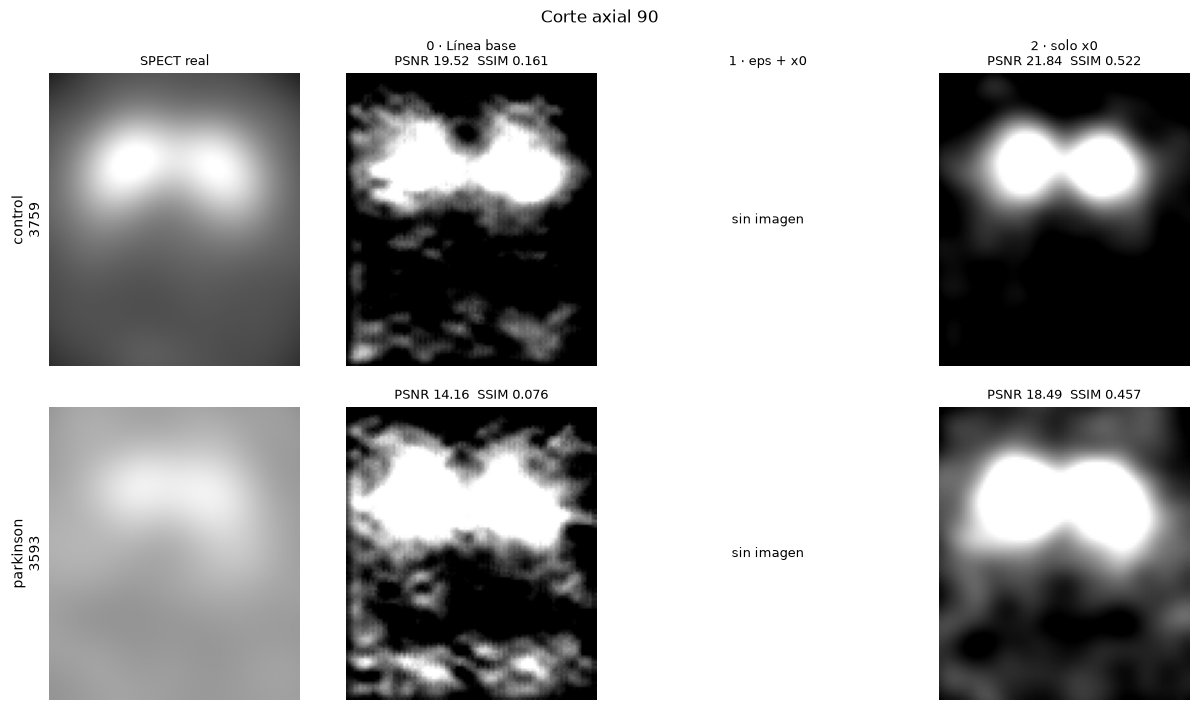

control 3759: corte 90 de 114
parkinson 3593: corte 90 de 114


In [24]:
# None = axial central. Un entero elige ese índice (eje axial, el último del volumen).
SLICE_INDEX = 90


def axial_slice(vol: np.ndarray, index: int | None) -> tuple[np.ndarray | None, int, int]:
    vol = np.asarray(vol)
    if vol.ndim == 4:
        vol = vol[0]
    depth = int(vol.shape[-1])
    chosen = depth // 2 if index is None else int(index)
    if chosen < 0 or chosen >= depth:
        return None, chosen, depth
    return vol[:, :, chosen], chosen, depth


def _frame(ax):
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)


if "cases" not in globals() or not cases:
    print("Ejecuta antes la celda de control y Parkinson para fijar los dos sujetos.")
else:
    columns = [("SPECT real", None)] + [(s["title"], s) for s in STAGES]
    n_rows, n_cols = len(cases), len(columns)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.1 * n_cols, 3.6 * n_rows))
    axes = np.atleast_2d(axes)
    used = []

    for row, (sid, name) in enumerate(cases):
        gt = load_gt(sid)
        vmin, vmax = np.percentile(gt, [1, 99])
        gt_img, gt_index, gt_depth = axial_slice(gt, SLICE_INDEX)
        used.append(f"{name} {sid}: corte {gt_index} de {gt_depth}")
        for col, (title, stage) in enumerate(columns):
            ax = axes[row, col]
            _frame(ax)
            if stage is None:
                img, chosen, depth = gt_img, gt_index, gt_depth
                metric = ""
            else:
                try:
                    syn = load_synthetic_volume_for(stage["exp"], stage["run_id"], sid)
                except FileNotFoundError:
                    ax.set_title(title if row == 0 else "", fontsize=9)
                    ax.text(0.5, 0.5, "sin imagen", ha="center", va="center", transform=ax.transAxes, fontsize=9)
                    if col == 0:
                        ax.set_ylabel(f"{name}\n{sid}", fontsize=10)
                    continue
                img, chosen, depth = axial_slice(syn, SLICE_INDEX)
                metric = ""
                if stage["key"] in recon:
                    hit = recon[stage["key"]]
                    hit = hit[hit["ID"].astype(str) == sid]
                    if len(hit):
                        metric = f"\nPSNR {hit['PSNR'].iloc[0]:.2f}  SSIM {hit['SSIM'].iloc[0]:.3f}"
            if img is None:
                ax.set_title(title if row == 0 else "", fontsize=9)
                ax.text(
                    0.5,
                    0.5,
                    f"corte {chosen}\nfuera de 0..{depth - 1}",
                    ha="center",
                    va="center",
                    transform=ax.transAxes,
                    fontsize=9,
                )
                if col == 0:
                    ax.set_ylabel(f"{name}\n{sid}", fontsize=10)
                continue
            ax.imshow(np.rot90(img), cmap="gray", vmin=vmin, vmax=vmax)
            ax.set_title((title if row == 0 else "") + metric, fontsize=9)
            if col == 0:
                ax.set_ylabel(f"{name}\n{sid}", fontsize=10)

    corte = "central" if SLICE_INDEX is None else str(int(SLICE_INDEX))
    fig.suptitle(f"Corte axial {corte}", fontsize=12)
    fig.tight_layout()
    plt.show()
    print("\n".join(used))


## Siguiente corrida y lo que queda fuera

La clave `calib_roi3ch_uni_rois_reproc_x0_minmax_kl_calib` todavía no está en `STAGES`: no hay corrida que graficar. Reusa los AAE de minmax+KL, calibra el latente con `data_info/latent_stats_latent_Abeta_minmax_kl.json` y mantiene el clamp en ±4. El piso de copiar el mapa medio del train queda en `latent_MSE_mean_baseline` de `validation.csv`.

Mediano plazo, misma fase 2 y mismos AAE: más épocas, `clip_grad_norm_(..., 1.0)` y `CosineAnnealingLR`.

Experimento completo aparte: subir `KL_LAMBDA` de `1e-3` a `1e-1`. Eso reentrena los AAE y regenera los latentes.

Largo plazo, fuera de la difusión: descongelar el encoder MRI, pérdida de reconstrucción en el brazo condicional, `FILM_MODE=spatial_ms`, dropout de etiqueta y `ATTN_RES` en la resolución 3 del latente 24×28×29.

## Mejores y peores por PSNR

Los cuatro sujetos salen del test de la etapa actual, `x0_minmax_kl`. Dentro de cada clase se toma el mayor PSNR y el menor PSNR del volumen completo. El SSIM no entra en la elección.

La figura tiene una fila por caso y cuatro columnas: SPECT real, línea base, solo x0 y la etapa actual. Cada panel usa la ventana de su propio volumen (percentiles 1 y 99). La referencia, la línea base y x0 no están en la escala [0, 1] de `x0_minmax_kl`, así que una ventana común recortaría unas y apagaría otras. El número de cada reconstrucción es el PSNR de esa etapa en ese sujeto. El corte es el axial central.

,caso,ID,PSNR_x0_minmax_kl,PSNR_baseline,PSNR_x0
0,mejor control,3361,20.420,19.890,23.588
1,peor control,3554,16.174,17.325,16.559
2,mejor parkinson,3108,19.439,19.588,23.735
3,peor parkinson,3185,13.009,13.225,18.349


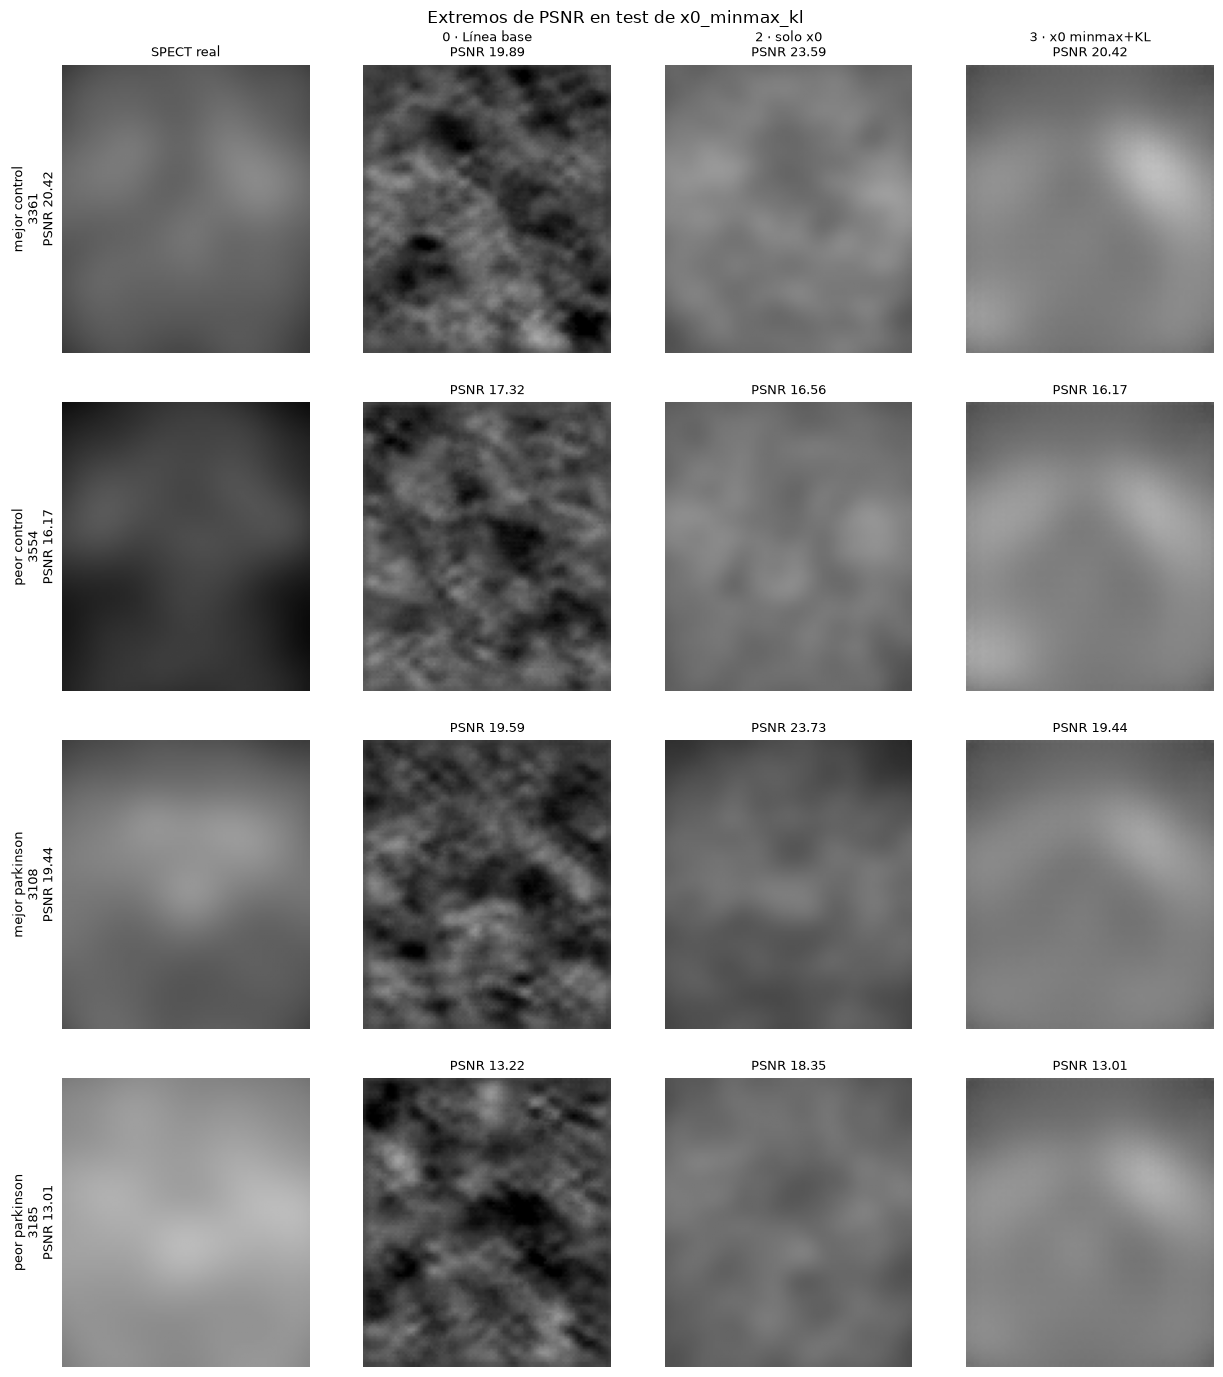

In [7]:
RANK_KEY = "x0_minmax_kl"
SHOW_KEYS = ("baseline", "x0", "x0_minmax_kl")


def extreme_subject(df: pd.DataFrame, label: float, best: bool) -> tuple[str, float] | None:
    subset = df[df["label"] == label]
    if subset.empty or "PSNR" not in subset.columns or subset["PSNR"].isna().all():
        return None
    idx = subset["PSNR"].idxmax() if best else subset["PSNR"].idxmin()
    row = subset.loc[idx]
    return str(row["ID"]), float(row["PSNR"])


def panel_window(vol: np.ndarray) -> tuple[float, float]:
    lo, hi = np.percentile(np.asarray(vol), [1, 99])
    if not np.isfinite(lo) or not np.isfinite(hi) or hi <= lo:
        lo, hi = float(np.min(vol)), float(np.max(vol))
    if hi <= lo:
        hi = lo + 1.0
    return float(lo), float(hi)


stages_by_key = {stage["key"]: stage for stage in STAGES}
rank_df = recon.get(RANK_KEY)

if rank_df is None or rank_df.empty:
    print(f"No hay reconstrucciones de test en '{RANK_KEY}' para elegir extremos.")
else:
    extremes = []
    for label, best, caption in (
        (0.0, True, "mejor control"),
        (0.0, False, "peor control"),
        (1.0, True, "mejor parkinson"),
        (1.0, False, "peor parkinson"),
    ):
        picked = extreme_subject(rank_df, label, best)
        if picked is None:
            print(f"Sin sujeto para {caption}.")
            continue
        extremes.append((picked[0], caption, picked[1]))

    summary_rows = []
    for sid, caption, rank_psnr in extremes:
        record = {"caso": caption, "ID": sid, f"PSNR_{RANK_KEY}": rank_psnr}
        for key in SHOW_KEYS:
            if key == RANK_KEY or key not in recon:
                continue
            hit = recon[key]
            hit = hit[hit["ID"].astype(str) == sid]
            record[f"PSNR_{key}"] = float(hit["PSNR"].iloc[0]) if len(hit) else np.nan
        summary_rows.append(record)
    display(pd.DataFrame(summary_rows))

    columns = [("SPECT real", None)] + [
        (stages_by_key[key]["title"], stages_by_key[key])
        for key in SHOW_KEYS
        if key in stages_by_key
    ]
    n_rows, n_cols = len(extremes), len(columns)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.2 * n_cols, 3.5 * n_rows))
    axes = np.atleast_2d(axes)

    for row, (sid, caption, rank_psnr) in enumerate(extremes):
        gt = load_gt(sid)
        for col, (title, stage) in enumerate(columns):
            ax = axes[row, col]
            _frame(ax)
            if stage is None:
                vol = gt
                metric = ""
            else:
                try:
                    vol = load_synthetic_volume_for(stage["exp"], stage["run_id"], sid)
                except FileNotFoundError:
                    ax.set_title(title if row == 0 else "", fontsize=9)
                    ax.text(0.5, 0.5, "sin imagen", ha="center", va="center", transform=ax.transAxes, fontsize=9)
                    if col == 0:
                        ax.set_ylabel(f"{caption}\n{sid}\nPSNR {rank_psnr:.2f}", fontsize=9)
                    continue
                metric = ""
                if stage["key"] in recon:
                    hit = recon[stage["key"]]
                    hit = hit[hit["ID"].astype(str) == sid]
                    if len(hit):
                        metric = f"\nPSNR {hit['PSNR'].iloc[0]:.2f}"
            vmin, vmax = panel_window(vol)
            ax.imshow(np.rot90(axial_mid(vol)), cmap="gray", vmin=vmin, vmax=vmax)
            ax.set_title((title if row == 0 else "") + metric, fontsize=9)
            if col == 0:
                ax.set_ylabel(f"{caption}\n{sid}\nPSNR {rank_psnr:.2f}", fontsize=9)

    fig.suptitle(f"Extremos de PSNR en test de {RANK_KEY}", fontsize=12)
    fig.tight_layout()
    plt.show()